# Trabajo Práctico 2 — Aprendizaje Supervisado
**Ciencia de Datos 2 · Comparación de modelos clásicos de clasificación con validación cruzada**

**Autor:** Santiago Londoño Pérez · Economía, UNAULA


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, roc_curve, ConfusionMatrixDisplay

SEED = 42
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

## 1. Dataset
Se usa el **Breast Cancer Wisconsin (Diagnostic)** (UCI / disponible en Kaggle). Cada fila es una biopsia por aspiración con aguja fina; las 30 variables describen características de los núcleos celulares (radio, textura, perímetro, área, suavidad, concavidad, etc., en media, error estándar y "peor valor").

**Cumple los criterios del enunciado:**
- Variable objetivo binaria y claramente definida → **clasificación** (`1 = maligno`, `0 = benigno`).
- 30 predictoras, **todas numéricas** (≥ 5 requeridas) → no hace falta codificar categóricas.
- Sin valores faltantes ni columnas irrelevantes (se verifica abajo).

In [3]:
raw = load_breast_cancer(as_frame=True)
X = raw.data.copy()
y = (1 - raw.target).rename("maligno")   # en sklearn 0=maligno; se invierte para que 1 = clase de interés

print(f"Observaciones: {X.shape[0]} | Predictoras: {X.shape[1]}")
print(f"Valores faltantes: {int(X.isna().sum().sum())} | Duplicados: {int(X.duplicated().sum())}")
print(f"Tipos: {X.dtypes.unique().tolist()}")
print("\nBalance de clases:")
print(y.value_counts().rename({0:'Benigno',1:'Maligno'}).to_frame('n').assign(pct=lambda d: (100*d.n/d.n.sum()).round(1)))

Observaciones: 569 | Predictoras: 30
Valores faltantes: 0 | Duplicados: 0
Tipos: [dtype('float64')]

Balance de clases:
           n   pct
maligno           
Benigno  357  62.7
Maligno  212  37.3


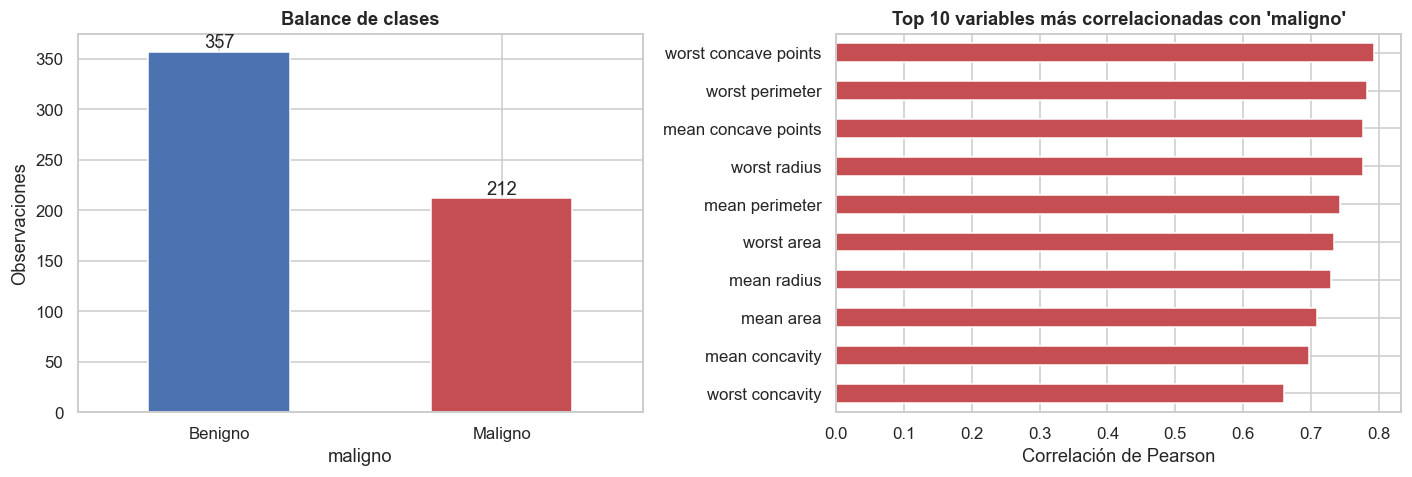

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
y.map({0:'Benigno',1:'Maligno'}).value_counts().plot.bar(ax=ax[0], color=["#4C72B0","#C44E52"], rot=0)
ax[0].set_title("Balance de clases"); ax[0].set_ylabel("Observaciones")
for p in ax[0].patches: ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")

corr_y = X.corrwith(y).sort_values()
corr_y.tail(10).plot.barh(ax=ax[1], color="#C44E52")
ax[1].set_title("Top 10 variables más correlacionadas con 'maligno'"); ax[1].set_xlabel("Correlación de Pearson")
plt.tight_layout(); plt.show()

**Lectura:** el dataset tiene **569 observaciones, 30 predictoras numéricas, sin faltantes ni duplicados**. Las clases están moderadamente desbalanceadas (62,7 % benigno / 37,3 % maligno), lo que justifica **estratificar** las particiones y usar **ROC AUC**, una métrica que no depende del umbral de decisión. Las variables de tamaño y concavidad celular (radio, perímetro, puntos cóncavos) son las más asociadas con la malignidad; además, varias de ellas están muy correlacionadas entre sí (multicolinealidad), algo que afecta distinto a cada modelo.

## 2. Partición y preprocesamiento
**Partición estratificada 60 / 20 / 20** (entrenamiento / validación / prueba): se conserva la proporción de clases en cada subconjunto.

**Pipeline:** `StandardScaler` sobre todas las variables numéricas, empaquetado junto al modelo dentro de un `Pipeline`. Esto es clave: dentro de la validación cruzada el escalador se **reajusta en cada fold usando solo sus datos de entrenamiento**, evitando fuga de información (*data leakage*).

In [5]:
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)  # 0.25*0.8 = 0.20

split = pd.DataFrame({
    "n": [len(y_train), len(y_val), len(y_test)],
    "% del total": [round(100*len(s)/len(y),1) for s in (y_train, y_val, y_test)],
    "% malignos": [round(100*s.mean(),1) for s in (y_train, y_val, y_test)],
}, index=["Entrenamiento","Validación","Prueba"])
split

,n,% del total,% malignos
Entrenamiento,341,59.9,37.2
Validación,114,20.0,37.7
Prueba,114,20.0,36.8


In [6]:
num_cols = X.columns.tolist()
preprocess = ColumnTransformer([("num", StandardScaler(), num_cols)])

modelos = {
    "Regresión Logística": LogisticRegression(),
    "KNN":                 KNeighborsClassifier(),
    "Árbol de Decisión":   DecisionTreeClassifier(random_state=SEED),
    "SVM (RBF)":           SVC(),
}
pipes = {nombre: Pipeline([("prep", preprocess), ("modelo", m)]) for nombre, m in modelos.items()}
list(pipes)

['Regresión Logística', 'KNN', 'Árbol de Decisión', 'SVM (RBF)']

## 3. Modelos a comparar
Todos con **hiperparámetros por defecto** (solo se fija `random_state` en el árbol para reproducibilidad):

- **Regresión Logística** — modelo lineal, sesgo alto / varianza baja.
- **KNN** (k=5) — no paramétrico basado en distancias; por eso el escalado importa.
- **Árbol de Decisión** (sin poda) — muy flexible, tiende a sobreajustar.
- **SVM con kernel RBF** — frontera no lineal suave (se usa `decision_function`, válido para ROC AUC).

## 4. Evaluación: entrenamiento, validación y validación cruzada
Para cada modelo: (1) ROC AUC en entrenamiento, (2) ROC AUC en validación y (3) **validación cruzada estratificada de 5 folds** sobre el conjunto de entrenamiento, registrando cada fold, la media y la desviación estándar.

In [7]:
def puntaje(pipe, Xs, ys):
    """ROC AUC usando predict_proba si existe, o decision_function (p. ej. SVC)."""
    m = pipe.named_steps["modelo"]
    s = pipe.predict_proba(Xs)[:, 1] if hasattr(m, "predict_proba") else pipe.decision_function(Xs)
    return roc_auc_score(ys, s)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
filas, folds = [], {}
for nombre, pipe in pipes.items():
    pipe.fit(X_train, y_train)
    auc_tr  = puntaje(pipe, X_train, y_train)
    auc_val = puntaje(pipe, X_val, y_val)
    sc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    folds[nombre] = sc
    filas.append({"Modelo": nombre, "AUC Train": auc_tr, "AUC Val": auc_val,
                  "AUC CV (media)": sc.mean(), "AUC CV (std)": sc.std(ddof=1)})

res = pd.DataFrame(filas).set_index("Modelo")
res["Brecha Train−CV"] = res["AUC Train"] - res["AUC CV (media)"]
res["Brecha Val−CV"]   = res["AUC Val"]   - res["AUC CV (media)"]
print(res.round(4).to_string())
res.round(4).style.format("{:.4f}").background_gradient(subset=["AUC Val","AUC CV (media)"], cmap="Greens")

                     AUC Train  AUC Val  AUC CV (media)  AUC CV (std)  Brecha Train−CV  Brecha Val−CV
Modelo                                                                                               
Regresión Logística     0.9979   0.9957          0.9941        0.0088           0.0038         0.0017
KNN                     0.9965   0.9948          0.9739        0.0399           0.0226         0.0209
Árbol de Decisión       1.0000   0.8972          0.9364        0.0201           0.0636        -0.0392
SVM (RBF)               0.9965   0.9961          0.9936        0.0090           0.0029         0.0025


,AUC Train,AUC Val,AUC CV (media),AUC CV (std),Brecha Train−CV,Brecha Val−CV
Modelo,,,,,,
Regresión Logística,0.9979,0.9957,0.9941,0.0088,0.0038,0.0017
KNN,0.9965,0.9948,0.9739,0.0399,0.0226,0.0209
Árbol de Decisión,1.0000,0.8972,0.9364,0.0201,0.0636,-0.0392
SVM (RBF),0.9965,0.9961,0.9936,0.0090,0.0029,0.0025


In [8]:
tabla_folds = pd.DataFrame(folds, index=[f"Fold {i}" for i in range(1, 6)]).T
tabla_folds["Media"] = tabla_folds.mean(axis=1)
tabla_folds["Desv. est."] = pd.DataFrame(folds).std(ddof=1).values
tabla_folds.round(4)

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Media,Desv. est.
Regresión Logística,0.9964,0.9973,0.9981,0.9786,1.0000,0.9941,0.0088
KNN,0.9043,0.9922,0.9963,0.9767,1.0000,0.9739,0.0399
Árbol de Decisión,0.9191,0.9643,0.9484,0.9335,0.9167,0.9364,0.0201
SVM (RBF),0.9919,1.0000,0.9972,0.9786,1.0000,0.9936,0.0090


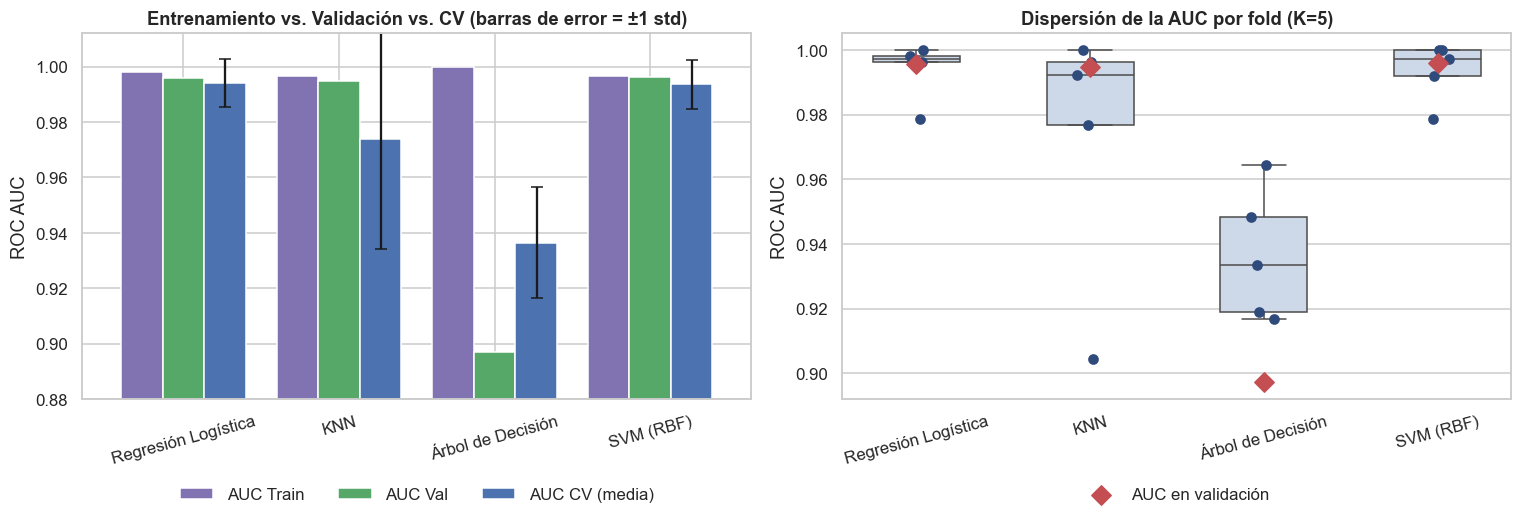

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# (a) Train vs Val vs CV
plot_df = res[["AUC Train","AUC Val","AUC CV (media)"]].rename(columns={"AUC CV (media)":"AUC CV (media)"})
plot_df.plot.bar(ax=ax[0], rot=15, width=0.8, color=["#8172B2","#55A868","#4C72B0"])
ax[0].errorbar(np.arange(len(res))+0.27, res["AUC CV (media)"], yerr=res["AUC CV (std)"], fmt="none", ecolor="k", capsize=4)
ax[0].set_ylim(0.88, 1.012); ax[0].set_ylabel("ROC AUC"); ax[0].set_xlabel(""); ax[0].set_title("Entrenamiento vs. Validación vs. CV (barras de error = ±1 std)")
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)

# (b) Boxplot de los folds con la AUC de validación superpuesta
sns.boxplot(data=pd.DataFrame(folds), ax=ax[1], width=0.5, color="#C9D9EC", fliersize=0)
sns.stripplot(data=pd.DataFrame(folds), ax=ax[1], color="#2F4B7C", size=7, jitter=0.08)
ax[1].scatter(range(len(res)), res["AUC Val"], marker="D", s=80, color="#C44E52", zorder=5, label="AUC en validación")
ax[1].set_title("Dispersión de la AUC por fold (K=5)"); ax[1].set_ylabel("ROC AUC"); ax[1].tick_params(axis="x", rotation=15)
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout(); plt.show()

### 4.1 ¿Qué dice la validación cruzada frente a la validación?

| Modelo | AUC Train | AUC CV (media ± std) | AUC Val | Lectura |
|---|---|---|---|---|
| Regresión Logística | 0,998 | 0,994 ± 0,009 | 0,996 | Todo coherente: brechas mínimas (≈0,002–0,004). |
| SVM (RBF) | 0,997 | 0,994 ± 0,009 | 0,996 | Prácticamente idéntico a la logística. |
| KNN | 0,997 | 0,974 ± 0,040 | 0,995 | La CV revela **inestabilidad**: un fold cae a 0,904. La validación (0,995) luce más optimista que la media de CV. |
| Árbol de Decisión | 1,000 | 0,936 ± 0,020 | 0,897 | **Sobreajuste claro**: memoriza el entrenamiento (AUC = 1) y cae ≈10 puntos en validación. |

**Conclusiones que se pueden extraer:**
1. **La CV aporta lo que la validación no puede: dispersión.** La validación es un único número (114 observaciones); la CV muestra cuánto varía el desempeño entre subconjuntos. En KNN, la validación (0,995) ocultaba una desviación estándar de 0,040.
2. **Para el árbol, ambas fuentes coinciden en lo importante:** generaliza mucho peor que el resto. Su validación (0,897) queda además cerca de 2 desviaciones por debajo de su media en CV, señal de que la partición de validación le resultó particularmente desfavorable o de que el modelo es muy sensible a los datos.
3. **Un árbol sin poda produce probabilidades casi binarias (0/1) en las hojas**, por lo que su curva ROC tiene muy pocos puntos y su AUC equivale aproximadamente a la exactitud balanceada; es parte de por qué rinde peor en esta métrica.
4. **Las diferencias entre los tres mejores (≈0,001–0,002) son mucho menores que la desviación estándar de CV (≈0,009):** con estos datos no son distinguibles.

### 4.2 ¿Qué modelo generaliza mejor?

**Regresión Logística y SVM (RBF) generalizan mejor y están prácticamente empatados**: ambos tienen la AUC media en CV más alta (0,994), la menor dispersión entre folds (≈0,009) y brechas train–CV / validación–CV por debajo de 0,004. Después viene **KNN**, con buena AUC pero mucha varianza entre folds (0,040), y por último el **Árbol de Decisión**, que sobreajusta (AUC de entrenamiento = 1,0 vs. 0,936 en CV).

**Decisión:** se elige la **Regresión Logística**. Tiene la media de CV más alta y, dado el empate técnico con la SVM, se prefiere por **parsimonia e interpretabilidad** (coeficientes explicables, menor costo, sin kernel). Ojo: la razón no es que sea "significativamente mejor", sino que **no hay evidencia para preferir un modelo más complejo**.

### 4.3 Robustez: ¿cuánto depende la conclusión de *una* partición?
La validación (114 observaciones) es una única muestra: su AUC también tiene ruido. Para dimensionarlo, se repite **todo el procedimiento (partición 60/20/20 → ajuste → AUC en validación) con 30 semillas distintas**. Este análisis es complementario y **no usa el conjunto de prueba** de la partición principal para tomar decisiones.

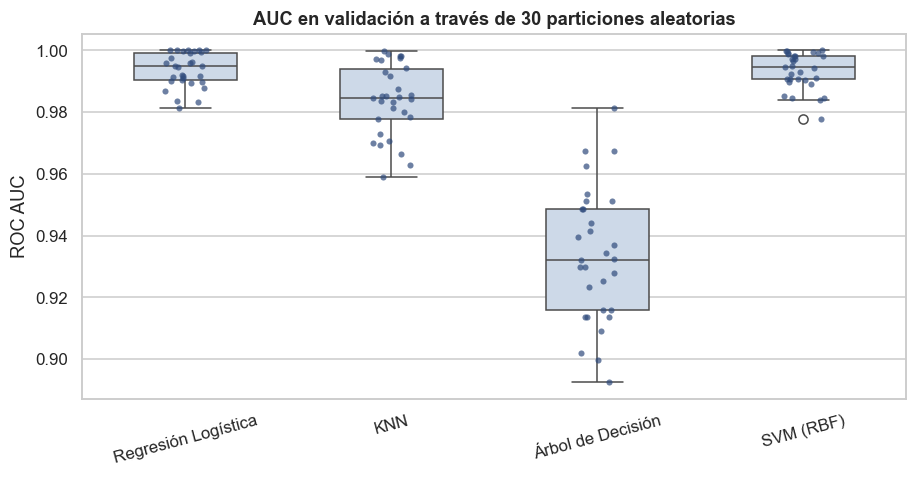

,mean,std,min,max
Regresión Logística,0.9936,0.0055,0.9813,1.0000
KNN,0.9839,0.0115,0.9589,0.9997
Árbol de Decisión,0.9335,0.0216,0.8926,0.9813
SVM (RBF),0.9933,0.0058,0.9777,1.0000


In [10]:
rng_seeds = range(100, 130)
rob = {n: [] for n in pipes}
for s in rng_seeds:
    Xa, _, ya, _ = train_test_split(X, y, test_size=0.20, stratify=y, random_state=s)
    Xt, Xv, yt, yv = train_test_split(Xa, ya, test_size=0.25, stratify=ya, random_state=s)
    for n, p in pipes.items():
        pc = clone(p).fit(Xt, yt)
        rob[n].append(puntaje(pc, Xv, yv))
rob = pd.DataFrame(rob)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.boxplot(data=rob, ax=ax, width=0.5, color="#C9D9EC")
sns.stripplot(data=rob, ax=ax, color="#2F4B7C", size=4, alpha=.7)
ax.set_title("AUC en validación a través de 30 particiones aleatorias"); ax.set_ylabel("ROC AUC"); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()
rob.agg(["mean","std","min","max"]).T.round(4)

**Resultado:** el ordenamiento se confirma y se vuelve más claro: **{Regresión Logística ≈ SVM} > KNN > Árbol**. Medias de AUC en validación a través de 30 particiones: 0,9936 (LR), 0,9933 (SVM), 0,9839 (KNN) y 0,9335 (Árbol). LR y SVM se solapan por completo, y de hecho en la partición principal la SVM quedó apenas por encima en validación (0,9961 vs. 0,9957) mientras que en CV fue al revés: **elegir entre ellos con una sola partición sería cuestión de azar**. Esto ilustra por qué la decisión se apoya en la CV y no en un único conjunto de validación.

## 5. Evaluación final en el conjunto de prueba
Se elige el modelo con **mejor desempeño promedio en validación cruzada** (desempate: menor desviación estándar y coherencia con la validación), se **reentrena con todo el conjunto de entrenamiento** y se evalúa **una sola vez** sobre prueba.

In [11]:
orden = res.sort_values(["AUC CV (media)","AUC CV (std)"], ascending=[False, True])
mejor = orden.index[0]
print("Ranking por AUC CV (media):")
print(orden[["AUC CV (media)","AUC CV (std)","AUC Val"]].round(4))
print(f"\n>>> Modelo seleccionado: {mejor}")

final = Pipeline([("prep", preprocess), ("modelo", modelos[mejor].__class__(**modelos[mejor].get_params()))])
final.fit(X_train, y_train)
auc_test = puntaje(final, X_test, y_test)

cv_m, cv_s = res.loc[mejor, "AUC CV (media)"], res.loc[mejor, "AUC CV (std)"]
print(f"\nAUC en prueba: {auc_test:.4f}")
print(f"AUC CV: {cv_m:.4f} ± {cv_s:.4f}  →  rango [{cv_m-cv_s:.4f}, {cv_m+cv_s:.4f}]")
print(f"AUC validación: {res.loc[mejor,'AUC Val']:.4f}")
print("(El límite superior teórico de la AUC es 1.0)")
print("¿Prueba dentro de CV ± 1 std?", cv_m-cv_s <= auc_test <= cv_m+cv_s)

# Incertidumbre de la AUC en prueba: bootstrap percentil (1000 remuestreos)
rng = np.random.default_rng(SEED)
m = final.named_steps["modelo"]
sc_test = final.predict_proba(X_test)[:,1] if hasattr(m,"predict_proba") else final.decision_function(X_test)
yt_arr = y_test.to_numpy(); boots = []
for _ in range(1000):
    idx = rng.integers(0, len(yt_arr), len(yt_arr))
    if yt_arr[idx].min() == yt_arr[idx].max(): continue
    boots.append(roc_auc_score(yt_arr[idx], sc_test[idx]))
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"IC 95% bootstrap de la AUC en prueba: [{lo:.4f}, {hi:.4f}]")

Ranking por AUC CV (media):
                     AUC CV (media)  AUC CV (std)  AUC Val
Modelo                                                    
Regresión Logística          0.9941        0.0088   0.9957
SVM (RBF)                    0.9936        0.0090   0.9961
KNN                          0.9739        0.0399   0.9948
Árbol de Decisión            0.9364        0.0201   0.8972

>>> Modelo seleccionado: Regresión Logística

AUC en prueba: 0.9954
AUC CV: 0.9941 ± 0.0088  →  rango [0.9853, 1.0028]
AUC validación: 0.9957
(El límite superior teórico de la AUC es 1.0)
¿Prueba dentro de CV ± 1 std? True
IC 95% bootstrap de la AUC en prueba: [0.9846, 1.0000]


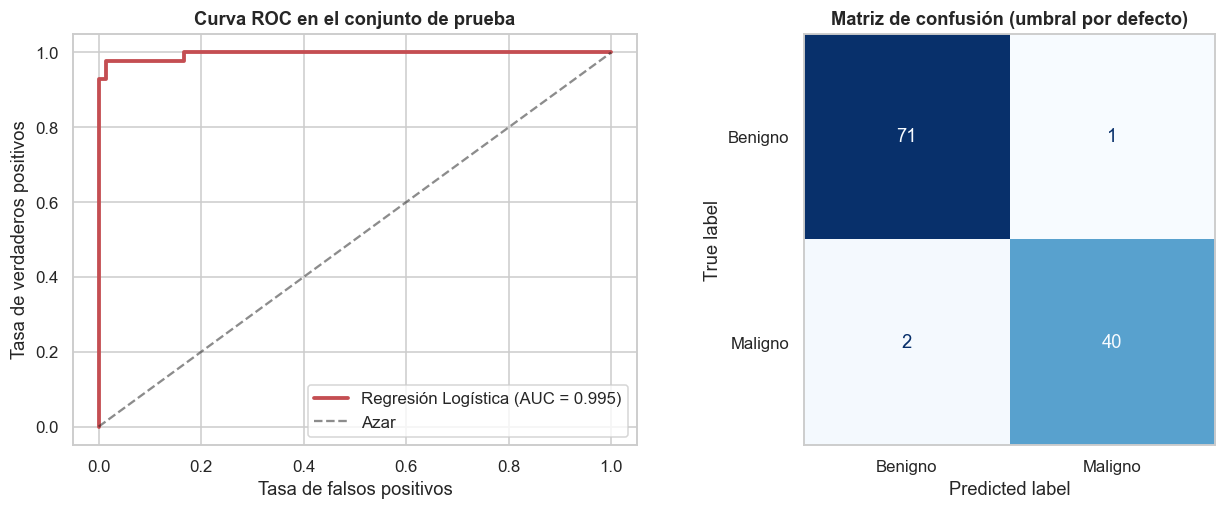

col_0         Pred benigno  Pred maligno
maligno                                 
Real benigno            71             1
Real maligno             2            40


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
fpr, tpr, _ = roc_curve(y_test, sc_test)
ax[0].plot(fpr, tpr, color="#C44E52", lw=2.5, label=f"{mejor} (AUC = {auc_test:.3f})")
ax[0].plot([0,1],[0,1],"k--",alpha=.5, label="Azar")
ax[0].set_xlabel("Tasa de falsos positivos"); ax[0].set_ylabel("Tasa de verdaderos positivos")
ax[0].set_title("Curva ROC en el conjunto de prueba"); ax[0].legend(loc="lower right")
ConfusionMatrixDisplay.from_estimator(final, X_test, y_test, display_labels=["Benigno","Maligno"], cmap="Blues", ax=ax[1], colorbar=False)
ax[1].set_title("Matriz de confusión (umbral por defecto)"); ax[1].grid(False)
plt.tight_layout(); plt.show()
print(pd.crosstab(y_test.map({0:"Real benigno",1:"Real maligno"}), pd.Series(final.predict(X_test), index=y_test.index).map({0:"Pred benigno",1:"Pred maligno"})))

### 5.1 ¿Se mantiene el comportamiento esperado?

**Sí, el comportamiento se mantiene.** La AUC en prueba (**0,9954**) cae dentro del rango esperado por CV (0,994 ± 0,009) y es prácticamente igual a la de validación (0,9957). El intervalo bootstrap al 95 % [0,985; 1,000] es coherente con la variabilidad vista entre folds, y su amplitud recuerda que con solo 114 observaciones de prueba la incertidumbre existe (el límite superior está topado en 1,0).

En la matriz de confusión (umbral 0,5): 71 verdaderos negativos, 1 falso positivo, 2 falsos negativos y 40 verdaderos positivos → **97,4 % de aciertos (111/114)**, sensibilidad 95,2 % y especificidad 98,6 %. En un contexto clínico los falsos negativos son más costosos, por lo que en la práctica se podría **bajar el umbral de decisión** para ganar sensibilidad a cambio de más falsos positivos; la AUC no captura esa preferencia.

## 6. Conclusiones y limitaciones

**Hallazgos principales**
- **Regresión Logística ≈ SVM > KNN > Árbol** en ROC AUC; la logística se selecciona por su mejor media en CV y por parsimonia.
- El **árbol sin poda sobreajusta** (AUC train = 1,0; validación = 0,897) y el **KNN es inestable** entre folds (std = 0,040).
- En prueba, el modelo final logra **AUC = 0,995**, consistente con CV y validación: el procedimiento de selección **no sobreestimó** el desempeño.

**Lecciones sobre selección de modelos**
1. Comparar siempre **media y dispersión** (CV), no un único número.
2. Diferencias menores que la desviación estándar entre folds **no son evidencia** de superioridad; ante empate, elegir el modelo más simple.
3. El conjunto de **prueba se usa una sola vez**, después de decidir.
4. Incluir el escalado **dentro del pipeline** evita fuga de información en la CV.

**Limitaciones**
- Dataset "fácil" (AUC > 0,99): cerca del techo, las diferencias entre modelos se comprimen.
- Hiperparámetros por defecto, por consigna: KNN (k) y el árbol (profundidad) probablemente mejorarían con ajuste, achicando las brechas.
- Prueba con solo 114 observaciones; una sola base de datos y sin validación externa, por lo que **no es apto para uso clínico real** sin evaluación adicional.